# 04 · Роль Маркета, сценарная модель, монетизация и целевой путь бизнеса

**Отвечает на вопросы кейса №3 и №5:** инструменты и их эффект для бизнеса и VK;
целевой путь бизнеса от первого контакта до продажи с развилками.

## Принципы модели
1. **Объёмы считаем от платформенных метрик**, а не экстраполяцией выборки (см. ноутбук 00):
   выборка сообществ покрывает 0,64% платформенного GMV.
2. **Эффекты инструментов берём скорректированными** (PSM/логит из ноутбука 02), а не наивными.
3. Все допущения — **явные параметры в одном словаре**, чтобы команда могла их менять и спорить.
4. Три сценария (консервативный / базовый / агрессивный) + чувствительность.
5. Эффект показываем **с двух сторон**: что получает бизнес и что получает ВКонтакте.

In [1]:
import sys, warnings, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vkcase import data, analysis as an, viz
from vkcase.config import VK, PARTNER, GOOD, BAD, GREY, VK_MARKET_SELLERS_PUBLIC

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
%matplotlib inline

d = data.load_all()
b = an.add_scenario_segment(d["biz"])
t = d["totals"]
num = lambda m, c="Маркет Вконтакте": float(pd.to_numeric(pd.Series([t.loc[m, c]]), errors="coerce").iloc[0])
f = an.funnel_table(t).set_index("segment")
prof = an.segment_profile(b).set_index("segment")
kn = json.loads((data.OUT / "key_numbers.json").read_text(encoding="utf-8"))

BASE = {
    "opens": f.loc["Маркет ВКонтакте", "card_opens"],
    "click_rate": f.loc["Маркет ВКонтакте", "click_rate_open_to_click"],
    "click2order": f.loc["Маркет ВКонтакте", "click_to_order"],
    "orders": f.loc["Маркет ВКонтакте", "orders"],
    "aov": f.loc["Маркет ВКонтакте", "aov"],
    "gmv": f.loc["Маркет ВКонтакте", "gmv"],
    "buyers": f.loc["Маркет ВКонтакте", "buyers"],
    "opb": f.loc["Маркет ВКонтакте", "orders_per_buyer"],
    "paid_share": num("Оплаченные заказы") / num("Оформленные заказы"),
    "pt_click_rate": f.loc["Партнёр 1", "click_rate_open_to_click"],
    "pt_click2order": f.loc["Партнёр 1", "click_to_order"],
    "pt_opb": f.loc["Партнёр 1", "orders_per_buyer"],
}
pd.Series(BASE).round(4).to_frame("база (сентябрь 2026)")

,база (сентябрь 2026)
opens,1.935125e+08
click_rate,3.080000e-02
click2order,6.930000e-02
orders,4.137400e+05
aov,3.781473e+03
gmv,1.564547e+09
buyers,2.961480e+05
opb,1.397100e+00
paid_share,1.190000e-02
pt_click_rate,4.216000e-01


## 1. Рычаги и их обоснование

| Рычаг | Что делаем | Якорь из данных |
|---|---|---|
| **L1. Карточка = сделка** | кнопка «Купить» с чекаутом, доставкой и оплатой по умолчанию | шаг открытие→нажатие 3,08% у Маркета против 42,16% у Партнёра; на этот шаг приходится 106% разрыва |
| **L2. Товарный контент (шопсы)** | товарные карточки в постах/клипах + реферальная программа | товарный контент публикуют 3,1% сообществ; 92,7% открытий Партнёра — из контента |
| **L3. Релевантность ассортимента** | убрать «мёртвый» трафик, привести категории к спросу | 46% открытий Маркета в категориях с конверсией <0,1% |
| **L4. Повторные покупки** | профиль покупателя, избранное, повторный заказ, снижение цены | 1,4 заказа/покупателя против 1,7 у Партнёра; повторных 19% против 26,6% |
| **L5. Активация сообществ** | импорт каталога, доставка/оплата «из коробки», онбординг | 94,8% подключивших чекаут не продают; PSM-эффект доставки +3,2 п.п. |

In [2]:
# Параметры сценариев. Меняйте здесь — все расчёты ниже пересчитаются.
SCEN = {
    "Консервативный": dict(
        click_rate=0.050,      # 3,08% → 5,0% (12% уровня Партнёра)
        click2order=0.080,     # 6,93% → 8,0%
        opens_growth=0.00,     # трафик не растёт
        aov=3600,              # slight mix shift
        opb=1.45,
        paid_share=0.25,       # доля заказов с оплатой внутри VK
        take_rate=0.03,
        # активация сообществ
        s4_att_pp=1.6, s4_coverage=0.35,
        s3_coverage=0.30, s2_coverage=0.10,
        s56_volume_growth=0.20,
        subscription_price=500, subscription_uptake=0.05,
        ads_uplift=0.10,
    ),
    "Базовый": dict(
        click_rate=0.080, click2order=0.100, opens_growth=0.10, aov=3300, opb=1.55,
        paid_share=0.50, take_rate=0.05,
        s4_att_pp=3.2, s4_coverage=0.50,
        s3_coverage=0.50, s2_coverage=0.20,
        s56_volume_growth=0.40,
        subscription_price=1500, subscription_uptake=0.10,
        ads_uplift=0.25,
    ),
    "Агрессивный": dict(
        click_rate=0.150, click2order=0.120, opens_growth=0.25, aov=2900, opb=1.70,
        paid_share=0.70, take_rate=0.07,
        s4_att_pp=7.3, s4_coverage=0.65,
        s3_coverage=0.70, s2_coverage=0.35,
        s56_volume_growth=0.60,
        subscription_price=3000, subscription_uptake=0.20,
        ads_uplift=0.50,
    ),
}
pd.DataFrame(SCEN).T.round(3)

,click_rate,click2order,opens_growth,aov,opb,paid_share,take_rate,s4_att_pp,s4_coverage,s3_coverage,s2_coverage,s56_volume_growth,subscription_price,subscription_uptake,ads_uplift
Консервативный,0.05,0.08,0.00,3600.0,1.45,0.25,0.03,1.6,0.35,0.3,0.10,0.2,500.0,0.05,0.10
Базовый,0.08,0.10,0.10,3300.0,1.55,0.50,0.05,3.2,0.50,0.5,0.20,0.4,1500.0,0.10,0.25
Агрессивный,0.15,0.12,0.25,2900.0,1.70,0.70,0.07,7.3,0.65,0.7,0.35,0.6,3000.0,0.20,0.50


## 2. Платформенный эффект: заказы и GMV внутри ВКонтакте

Модель воронки: `заказы = открытия карточки × конверсия в нажатие × конверсия нажатия в заказ`.
Это ровно те шаги, где данные показывают разрыв, поэтому модель не «изобретает» механику.

In [3]:
rows = []
for name, p in SCEN.items():
    opens = BASE["opens"] * (1 + p["opens_growth"])
    clicks = opens * p["click_rate"]
    orders = clicks * p["click2order"]
    gmv = orders * p["aov"]
    buyers = orders / p["opb"]
    rows.append({
        "сценарий": name, "открытия карточки": opens, "нажатия кнопки": clicks,
        "заказы/мес": orders, "прирост заказов": orders - BASE["orders"],
        "прирост заказов, %": (orders / BASE["orders"] - 1) * 100,
        "GMV/мес, ₽": gmv, "прирост GMV, ₽": gmv - BASE["gmv"],
        "покупатели/мес": buyers, "средний чек, ₽": p["aov"],
        "заказов на покупателя": p["opb"],
        "оплаченные заказы/мес": orders * p["paid_share"],
        "оплаченный GMV/мес, ₽": gmv * p["paid_share"],
    })
platform = pd.DataFrame(rows)
data.save_table(platform, "04_platform_scenarios")
platform.round(0)

,сценарий,открытия карточки,нажатия кнопки,заказы/мес,прирост заказов,"прирост заказов, %","GMV/мес, ₽","прирост GMV, ₽",покупатели/мес,"средний чек, ₽",заказов на покупателя,оплаченные заказы/мес,"оплаченный GMV/мес, ₽"
0,Консервативный,193512461.0,9675623.0,774050.0,360310.0,87.0,2.786579e+09,1.222033e+09,533827.0,3600,1.0,193512.0,6.966449e+08
1,Базовый,212863707.0,17029097.0,1702910.0,1289170.0,312.0,5.619602e+09,4.055055e+09,1098651.0,3300,2.0,851455.0,2.809801e+09
2,Агрессивный,241890576.0,36283586.0,4354030.0,3940290.0,952.0,1.262669e+10,1.106214e+10,2561194.0,2900,2.0,3047821.0,8.838682e+09


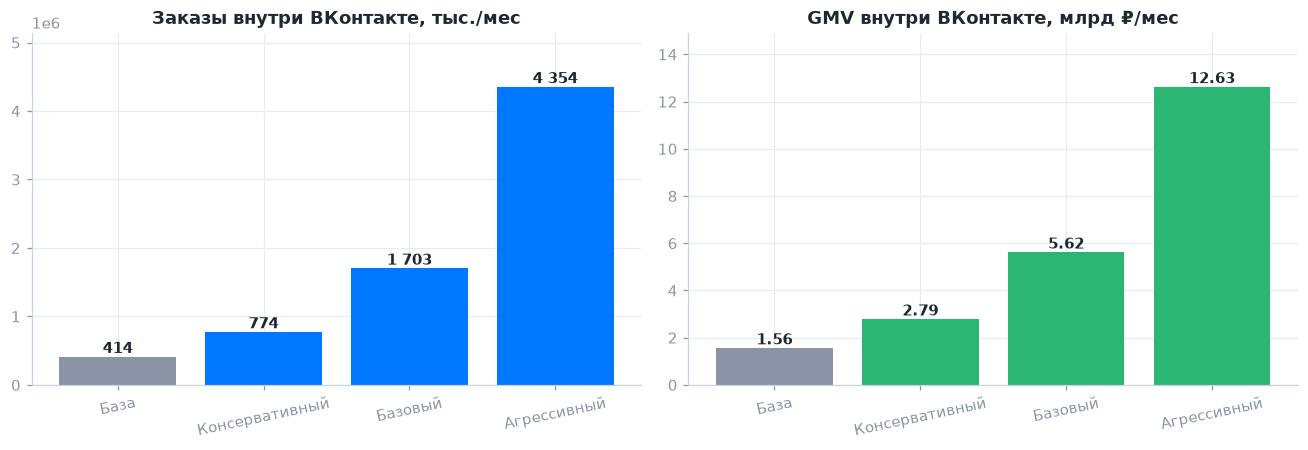

WindowsPath('C:/Users/Степан/Desktop/workspace/outputs/figures/04_platform_scenarios.png')

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = ["База"] + list(SCEN.keys())
orders_vals = [BASE["orders"]] + platform["заказы/мес"].tolist()
gmv_vals = [BASE["gmv"] / 1e9] + (platform["GMV/мес, ₽"] / 1e9).tolist()
axes[0].bar(labels, orders_vals, color=[GREY, VK, VK, VK])
axes[0].set_title("Заказы внутри ВКонтакте, тыс./мес")
for i, v in enumerate(orders_vals):
    axes[0].text(i, v, f"{v/1000:,.0f}".replace(",", " "), ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(0, max(orders_vals) * 1.18)
axes[1].bar(labels, gmv_vals, color=[GREY, GOOD, GOOD, GOOD])
axes[1].set_title("GMV внутри ВКонтакте, млрд ₽/мес")
for i, v in enumerate(gmv_vals):
    axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(0, max(gmv_vals) * 1.18)
for ax in axes: ax.tick_params(axis="x", rotation=12)
fig.tight_layout(); viz.save(fig, "04_platform_scenarios")

**Проверка на реализуемость.** Даже агрессивный сценарий (конверсия кнопки 15%) —
это лишь **36% от уровня Партнёра (42%)**, который уже работает на том же трафике ВКонтакте.
То есть мы не предполагаем чуда: мы предполагаем частичное закрытие доказанного разрыва.

In [5]:
for name, p in SCEN.items():
    print(f"{name}: конверсия кнопки {p['click_rate']:.1%} = {p['click_rate']/BASE['pt_click_rate']:.0%} уровня Партнёра; "
          f"конверсия нажатия в заказ {p['click2order']:.1%} = {p['click2order']/BASE['pt_click2order']:.0%} уровня Партнёра")

Консервативный: конверсия кнопки 5.0% = 12% уровня Партнёра; конверсия нажатия в заказ 8.0% = 59% уровня Партнёра
Базовый: конверсия кнопки 8.0% = 19% уровня Партнёра; конверсия нажатия в заказ 10.0% = 74% уровня Партнёра
Агрессивный: конверсия кнопки 15.0% = 36% уровня Партнёра; конверсия нажатия в заказ 12.0% = 89% уровня Партнёра


## 3. Эффект для бизнеса: сколько сообществ начнут продавать

Считаем на выборке (там есть сегменты), затем выражаем **относительный прирост**,
и только его переносим на платформенную базу продавцов. Это защищает от ошибки масштаба.

In [6]:
psm_att_pp = kn["02_drivers"]["psm_att_pp"]
psm_hi_pp = kn["02_drivers"]["psm_att_ci_high_pp"]
print(f"Из ноутбука 02: PSM ATT доставки = {psm_att_pp:.2f} п.п., верхняя граница ДИ = {psm_hi_pp:.2f} п.п.")
s4_rate = prof.loc["S4. Каталог + чекаут", "sell_rate"]
s5_rate = prof.loc["S5. Каталог + чекаут + доставка", "sell_rate"]
print(f"Базовая доля продающих: S4 = {s4_rate:.2%}, S5 = {s5_rate:.2%}")

rows = []
for name, p in SCEN.items():
    n4, n3, n2 = prof.loc["S4. Каталог + чекаут", "n"], prof.loc["S3. Витрина без чекаута", "n"], prof.loc["S2. Чекаут без каталога (аномалия)", "n"]
    n56 = prof.loc["S5. Каталог + чекаут + доставка", "n"] + prof.loc["S6. Полный стек (+оплата)", "n"]
    new4 = n4 * (p["s4_att_pp"] / 100) * p["s4_coverage"]
    new3 = n3 * max(0, s4_rate - prof.loc["S3. Витрина без чекаута", "sell_rate"]) * p["s3_coverage"]
    new2 = n2 * s4_rate * p["s2_coverage"]
    orders56 = (prof.loc["S5. Каталог + чекаут + доставка", "orders"] + prof.loc["S6. Полный стек (+оплата)", "orders"]) * p["s56_volume_growth"]
    total_new = new4 + new3 + new2
    rows.append({
        "сценарий": name,
        "S4: спящий магазин": new4, "S3: витрина без чекаута": new3, "S2: пустой чекаут": new2,
        "новых продающих (выборка)": total_new,
        "прирост продающих, %": total_new / b.has_order.sum(),
        "доп. заказы у S5/S6": orders56,
        "доля продающих в выборке: было": b.has_order.mean(),
        "доля продающих в выборке: станет": (b.has_order.sum() + total_new) / len(b),
    })
activation = pd.DataFrame(rows)
data.save_table(activation, "04_activation_scenarios")
activation.round(3)

Из ноутбука 02: PSM ATT доставки = 3.22 п.п., верхняя граница ДИ = 7.14 п.п.
Базовая доля продающих: S4 = 5.30%, S5 = 17.12%


,сценарий,S4: спящий магазин,S3: витрина без чекаута,S2: пустой чекаут,новых продающих (выборка),"прирост продающих, %",доп. заказы у S5/S6,доля продающих в выборке: было,доля продающих в выборке: станет
0,Консервативный,16.363,2.992,11.118,30.474,0.102,320.6,0.031,0.034
1,Базовый,46.752,4.987,22.237,73.976,0.248,641.2,0.031,0.038
2,Агрессивный,138.649,6.982,38.914,184.546,0.619,961.8,0.031,0.049


In [7]:
sellers_base_rate = b.loc[b.sku_active > 0, "has_order"].mean()
platform_sellers = []
for name, p in SCEN.items():
    rel = activation.loc[activation.сценарий == name, "прирост продающих, %"].iloc[0]
    for base_rate in [sellers_base_rate, 0.15, 0.25]:
        platform_sellers.append({
            "сценарий": name,
            "база продавцов с каталогом (публ.)": VK_MARKET_SELLERS_PUBLIC,
            "доля продающих (допущение)": base_rate,
            "продающих сейчас": VK_MARKET_SELLERS_PUBLIC * base_rate,
            "относительный прирост": rel,
            "новых продающих бизнесов": VK_MARKET_SELLERS_PUBLIC * base_rate * rel,
        })
ps = pd.DataFrame(platform_sellers)
data.save_table(ps, "04_platform_sellers_sensitivity")
ps.round(0)

,сценарий,база продавцов с каталогом (публ.),доля продающих (допущение),продающих сейчас,относительный прирост,новых продающих бизнесов
0,Консервативный,200000,0.0,14390.0,0.0,1472.0
1,Консервативный,200000,0.0,30000.0,0.0,3068.0
2,Консервативный,200000,0.0,50000.0,0.0,5113.0
3,Базовый,200000,0.0,14390.0,0.0,3572.0
4,Базовый,200000,0.0,30000.0,0.0,7447.0
5,Базовый,200000,0.0,50000.0,0.0,12412.0
6,Агрессивный,200000,0.0,14390.0,1.0,8912.0
7,Агрессивный,200000,0.0,30000.0,1.0,18578.0
8,Агрессивный,200000,0.0,50000.0,1.0,30964.0


**Оговорка, которую нужно произнести на защите:** база «более 200 тыс. продавцов» —
публичная оценка из блога VK Рекламы. В выборке продают 3,1% всех сообществ и 7,2% сообществ
с каталогом; это микро-СМБ, а не вся платформенная база. Поэтому показываем
**чувствительность по трём базовым ставкам** (7,2% / 15% / 25%), а не одно число.
Целевая метрика кейса — «число бизнесов, подключивших инструменты продаж» — растёт
раньше и надёжнее, чем число заказов: это ведущий индикатор.

## 4. Монетизация: от «продажи трафика» к «участию в сделке»

Сегодня VK зарабатывает на рекламе, но данные показывают: **92% рекламодателей выборки
не получают измеримого заказа**, а связь трат с продажей статистически не значима (OR≈1,02).
Значит модель «продавать трафик» упирается в потолок: бизнес не видит результата.

Целевая модель — **три потока**, каждый из которых возможен только после замыкания сделки.

In [8]:
ads_base_sample = b.ad_spend.sum()
mon = []
for name, p in SCEN.items():
    orders = platform.loc[platform.сценарий == name, "заказы/мес"].iloc[0]
    gmv = platform.loc[platform.сценарий == name, "GMV/мес, ₽"].iloc[0]
    paid_gmv = gmv * p["paid_share"]
    commission = paid_gmv * p["take_rate"]
    new_sellers = ps[(ps.сценарий == name) & (ps["доля продающих (допущение)"] == sellers_base_rate)]["новых продающих бизнесов"].iloc[0]
    subs = (VK_MARKET_SELLERS_PUBLIC * sellers_base_rate + new_sellers) * p["subscription_uptake"] * p["subscription_price"]
    mon.append({
        "сценарий": name,
        "оплаченный GMV, ₽/мес": paid_gmv,
        "комиссия (take rate)": p["take_rate"],
        "выручка от комиссии, ₽/мес": commission,
        "подписчиков на инструменты": (VK_MARKET_SELLERS_PUBLIC * sellers_base_rate + new_sellers) * p["subscription_uptake"],
        "цена подписки, ₽/мес": p["subscription_price"],
        "выручка от подписки, ₽/мес": subs,
        "прирост рекламной выручки, %": p["ads_uplift"],
        "итого новая выручка (комиссия+подписка), ₽/мес": commission + subs,
        "итого новая выручка, ₽/год": (commission + subs) * 12,
    })
mon = pd.DataFrame(mon)
data.save_table(mon, "04_monetization")
mon.round(0)

,сценарий,"оплаченный GMV, ₽/мес",комиссия (take rate),"выручка от комиссии, ₽/мес",подписчиков на инструменты,"цена подписки, ₽/мес","выручка от подписки, ₽/мес","прирост рекламной выручки, %","итого новая выручка (комиссия+подписка), ₽/мес","итого новая выручка, ₽/год"
0,Консервативный,6.966449e+08,0.0,20899346.0,793.0,500,396547.0,0.0,21295893.0,2.555507e+08
1,Базовый,2.809801e+09,0.0,140490047.0,1796.0,1500,2694388.0,0.0,143184435.0,1.718213e+09
2,Агрессивный,8.838682e+09,0.0,618707716.0,4660.0,3000,13981165.0,0.0,632688881.0,7.592267e+09


In [9]:
print(f"Сегодня комиссия невозможна: оплачено внутри VK лишь {BASE['paid_share']:.2%} заказов")
print(f"Оплаченный GMV сейчас ≈ {BASE['gmv']*BASE['paid_share']:,.0f} ₽/мес → при 5% это {BASE['gmv']*BASE['paid_share']*0.05:,.0f} ₽/мес")
print("\nПотенциал при замыкании сделки:")
print(mon[["сценарий", "оплаченный GMV, ₽/мес", "выручка от комиссии, ₽/мес", "выручка от подписки, ₽/мес", "итого новая выручка, ₽/год"]].round(0).to_string(index=False))

Сегодня комиссия невозможна: оплачено внутри VK лишь 1.19% заказов
Оплаченный GMV сейчас ≈ 18,540,563 ₽/мес → при 5% это 927,028 ₽/мес

Потенциал при замыкании сделки:
      сценарий  оплаченный GMV, ₽/мес  выручка от комиссии, ₽/мес  выручка от подписки, ₽/мес  итого новая выручка, ₽/год
Консервативный            696644860.0                  20899346.0                    396547.0                 255550715.0
       Базовый           2809800934.0                 140490047.0                   2694388.0                1718213215.0
   Агрессивный           8838681656.0                 618707716.0                  13981165.0                7592266576.0


### 4.1. Чувствительность: что важнее всего

Меняем по одному параметру базового сценария на ±50% и смотрим влияние на заказы и на выручку.

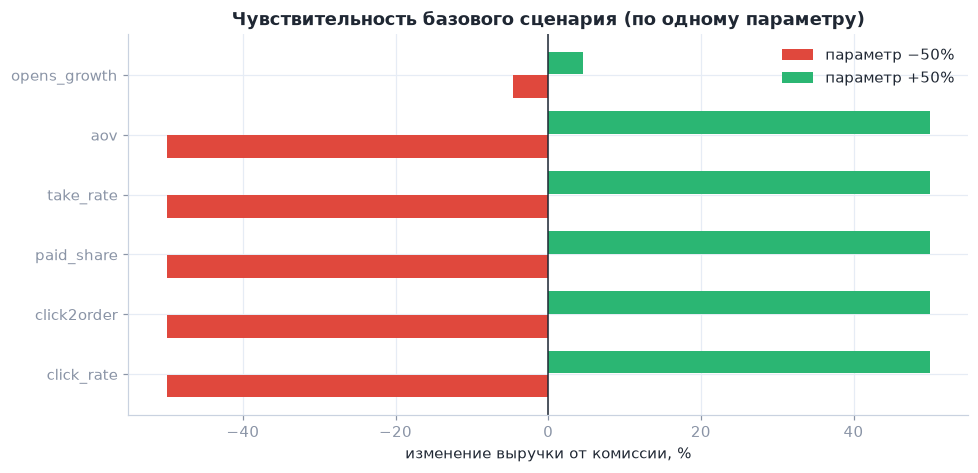

,параметр,изменение,заказы/мес,"Δ заказов, %","выручка от комиссии, ₽/мес","Δ выручки, %"
0,click_rate,−50%,851454.828,-0.500,7.024502e+07,-0.500
1,click_rate,+50%,2554364.485,0.500,2.107351e+08,0.500
2,click2order,−50%,851454.828,-0.500,7.024502e+07,-0.500
3,click2order,+50%,2554364.485,0.500,2.107351e+08,0.500
4,opens_growth,−50%,1625504.672,-0.045,1.341041e+08,-0.045
5,opens_growth,+50%,1780314.641,0.045,1.468760e+08,0.045
6,aov,−50%,1702909.657,0.000,7.024502e+07,-0.500
7,aov,+50%,1702909.657,0.000,2.107351e+08,0.500
8,paid_share,−50%,1702909.657,0.000,7.024502e+07,-0.500
9,paid_share,+50%,1702909.657,0.000,2.107351e+08,0.500


In [10]:
base_p = SCEN["Базовый"].copy()
def orders_of(p):
    return BASE["opens"] * (1 + p["opens_growth"]) * p["click_rate"] * p["click2order"]
def revenue_of(p):
    o = orders_of(p); g = o * p["aov"]
    return g * p["paid_share"] * p["take_rate"]
base_orders, base_rev = orders_of(base_p), revenue_of(base_p)
sens = []
for key in ["click_rate", "click2order", "opens_growth", "aov", "paid_share", "take_rate"]:
    for mult, tag in [(0.5, "−50%"), (1.5, "+50%")]:
        p = base_p.copy(); p[key] = base_p[key] * mult
        sens.append({"параметр": key, "изменение": tag,
                     "заказы/мес": orders_of(p), "Δ заказов, %": orders_of(p)/base_orders-1,
                     "выручка от комиссии, ₽/мес": revenue_of(p), "Δ выручки, %": revenue_of(p)/base_rev-1})
sens = pd.DataFrame(sens)
data.save_table(sens, "04_sensitivity")
pivot = sens.pivot(index="параметр", columns="изменение", values="Δ выручки, %").reindex(
    ["click_rate", "click2order", "paid_share", "take_rate", "aov", "opens_growth"])[["−50%", "+50%"]]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(pivot))
ax.barh(y - 0.2, pivot["−50%"] * 100, 0.38, label="параметр −50%", color=BAD)
ax.barh(y + 0.2, pivot["+50%"] * 100, 0.38, label="параметр +50%", color=GOOD)
ax.set_yticks(y, pivot.index); ax.axvline(0, color="#1F2733", lw=1)
ax.set_xlabel("изменение выручки от комиссии, %")
ax.set_title("Чувствительность базового сценария (по одному параметру)")
ax.legend()
fig.tight_layout(); viz.save(fig, "04_sensitivity")
sens.round(3)

**Вывод по чувствительности:** выручка одинаково чувствительна к конверсии кнопки,
к доле оплаченных заказов и к take rate. Но **конверсия кнопки — единственный параметр,
который мы можем двигать продуктом без изменения бизнес-модели** (остальные требуют
договорённостей с продавцами и платёжной инфраструктуры). Отсюда порядок действий:
сначала карточка и чекаут, потом платежи, потом комиссия.

## 5. Эффект с двух сторон (требование кейса)

Для каждого инструмента — что получает бизнес и что получает ВКонтакте.

In [11]:
two_sided = pd.DataFrame([
    ["Карточка с чекаутом по умолчанию (L1)",
     "сделка вместо переписки: не нужно вручную вести заказ; выше конверсия из интереса в заказ",
     "+1 п.п. конверсии кнопки = +134 тыс. заказов и +507 млн ₽ GMV в месяц; база для комиссии",
     "конверсия открытие→нажатие (3,08% → 8%)", "риск: продавцы без логистики не смогут исполнить заказ → нужен L5"],
    ["Доставка и оплата «из коробки» (L5)",
     "снимает главный барьер: не нужно договариваться с перевозчиком и эквайрингом",
     "рост доли оплаченных заказов с 1,2% до 50% (базовый сценарий) → появляется комиссия",
     "доля оплаченных заказов, ATT активации (+3,2 п.п. по PSM)", "риск: стоимость логистики и возвраты; нужен пилот"],
    ["Импорт каталога (Ozon/CSV/фото→карточка) (L5)",
     "каталог наполняется за минуты вместо недель; ассортимент — сильнейший предиктор продажи (OR≈1,5)",
     "каталог получают до 2 096 сообществ с пустым чекаутом (охват 10–35% по сценариям)",
     "доля сообществ с активным каталогом (40,6% → 55%)", "риск: качество и актуальность цен/наличия"],
    ["Шопсы + реферальная программа (L2)",
     "новый трафик от авторов без своего продакшена; оплата за результат",
     "рост открытий карточки; масштабирование доказанной модели Партнёра (92,7% открытий из контента)",
     "открытия карточки из контента, заказ/1000 открытий", "риск: каннибализация рекламы; нужна атрибуция"],
    ["Реклама с целью «заказ в чекауте» (L1+L5)",
     "видимый ROAS вместо охвата; бюджет идёт в измеримый результат",
     "рост удержания рекламодателя и бюджета (сейчас 92% плательщиков без измеримых заказов)",
     "ROAS, retention бюджета, доля рекламодателей с заказом", "риск: краткосрочно CPC выше, нужна оптимизация"],
    ["Профиль покупателя и повторные покупки (L4)",
     "повторные заказы дешевле привлечения; 1,4 → 1,7 заказа на покупателя",
     "+21% заказов без нового трафика", "заказов на покупателя, доля повторных (19% → 26%)",
     "риск: нужна история заказов и уведомления"],
    ["Подписка на инструменты продавца",
     "предсказуемые расходы вместо ставок за трафик; аналитика, автоответы, статусы",
     "диверсификация выручки от рекламы", "ARPA, доля платящих, churn", "риск: платить будут только после первых продаж"],
], columns=["инструмент", "эффект для бизнеса", "эффект для ВКонтакте", "метрика", "риск и как снимаем"])
data.save_table(two_sided, "04_two_sided_effects")
two_sided

,инструмент,эффект для бизнеса,эффект для ВКонтакте,метрика,риск и как снимаем
0,Карточка с чекаутом по умолчанию (L1),сделка вместо переписки: не нужно вручную вест...,+1 п.п. конверсии кнопки = +134 тыс. заказов и...,"конверсия открытие→нажатие (3,08% → 8%)",риск: продавцы без логистики не смогут исполни...
1,Доставка и оплата «из коробки» (L5),снимает главный барьер: не нужно договариватьс...,"рост доли оплаченных заказов с 1,2% до 50% (ба...","доля оплаченных заказов, ATT активации (+3,2 п...",риск: стоимость логистики и возвраты; нужен пилот
2,Импорт каталога (Ozon/CSV/фото→карточка) (L5),каталог наполняется за минуты вместо недель; а...,каталог получают до 2 096 сообществ с пустым ч...,"доля сообществ с активным каталогом (40,6% → 55%)",риск: качество и актуальность цен/наличия
3,Шопсы + реферальная программа (L2),новый трафик от авторов без своего продакшена;...,рост открытий карточки; масштабирование доказа...,"открытия карточки из контента, заказ/1000 откр...",риск: каннибализация рекламы; нужна атрибуция
4,Реклама с целью «заказ в чекауте» (L1+L5),видимый ROAS вместо охвата; бюджет идёт в изме...,рост удержания рекламодателя и бюджета (сейчас...,"ROAS, retention бюджета, доля рекламодателей с...","риск: краткосрочно CPC выше, нужна оптимизация"
5,Профиль покупателя и повторные покупки (L4),"повторные заказы дешевле привлечения; 1,4 → 1,...",+21% заказов без нового трафика,"заказов на покупателя, доля повторных (19% → 26%)",риск: нужна история заказов и уведомления
6,Подписка на инструменты продавца,предсказуемые расходы вместо ставок за трафик;...,диверсификация выручки от рекламы,"ARPA, доля платящих, churn",риск: платить будут только после первых продаж


## 6. Целевой путь бизнеса: от первого контакта до продажи, с развилками

Путь строится **от роли Маркета** (инфраструктура, а не destination): сообщество — «магазин»,
Маркет — товарный слой, поиск и контент — входы, чекаут — сделка.

### 6.1. Общая схема с развилками

In [12]:
journey = pd.DataFrame([
    ["0. Первый контакт", "узнаёт о продажах в VK (реклама, кейсы, рекомендация)",
     "все", "сообщество с целью «Развивать бизнес», чек-лист готовности",
     "создано сообщество с бизнес-инструментами", "—"],
    ["1. Развилка: есть ли товар?", "определяем сценарий: свой товар / товар партнёра / только услуги",
     "все", "опрос из 3 вопросов + автоопределение по контенту",
     "доля сообществ, прошедших маршрутизацию", "услуги → трек «заявки» (вне фокуса кейса)"],
    ["2a. Свой товар, каталога нет", "S2: пустой чекаут (2 096 в выборке)", "S2",
     "импорт каталога: Ozon/CSV/фото→карточка, автоцены",
     "доля с активным каталогом; время до первой карточки", "нет товара физически → трек «предзаказ/хендмейд»"],
    ["2b. Свой товар, каталог есть", "S3/S4 (3 242 в выборке)", "S3, S4",
     "чекаут по умолчанию + шаблоны доставки", "доля с чекаутом и доставкой", "—"],
    ["3. Настройка сделки", "главный барьер: исполнение заказа", "S3, S4, S5",
     "доставка «из коробки», оплата внутри VK, статусы, возвраты",
     "доля с полным стеком (сейчас <1%)", "самовывоз/локальная доставка → упрощённый стек"],
    ["4. Первый трафик", "нужны первые посетители карточки", "все товарные",
     "шопсы в постах/клипах, товарный поиск, SEO карточки",
     "открытия карточки на сообщество; CTR из контента (сейчас <0,3%)",
     "нет контента → реклама на карточку; есть авторы → реферальная программа"],
    ["5. Первая продажа", "момент истины: 94,8% подключивших чекаут до неё не доходят", "все товарные",
     "кнопка «Купить», оплата в 1 клик, подтверждение и трекинг",
     "доля сообществ с ≥1 заказом (3,1% → 6–10%)", "нет заказа за 14 дней → триггерная помощь и разбор карточки"],
    ["6. Повторные продажи", "удержание покупателя", "S5, S6",
     "профиль покупателя, избранное, снижение цены, повторный заказ",
     "заказов на покупателя 1,4 → 1,7", "—"],
    ["7. Масштабирование", "рост объёма и платных инструментов", "S5, S6",
     "реклама с целью «заказ», реферальная программа, подписка Pro",
     "GMV на продавца, ROAS, доля платящих", "—"],
], columns=["этап", "задача бизнеса", "сегменты", "инструменты VK", "метрика этапа", "развилка / альтернативный путь"])
data.save_table(journey, "04_business_journey")
journey

,этап,задача бизнеса,сегменты,инструменты VK,метрика этапа,развилка / альтернативный путь
0,0. Первый контакт,"узнаёт о продажах в VK (реклама, кейсы, рекоме...",все,"сообщество с целью «Развивать бизнес», чек-лис...",создано сообщество с бизнес-инструментами,—
1,1. Развилка: есть ли товар?,определяем сценарий: свой товар / товар партнё...,все,опрос из 3 вопросов + автоопределение по контенту,"доля сообществ, прошедших маршрутизацию",услуги → трек «заявки» (вне фокуса кейса)
2,"2a. Свой товар, каталога нет",S2: пустой чекаут (2 096 в выборке),S2,"импорт каталога: Ozon/CSV/фото→карточка, автоцены",доля с активным каталогом; время до первой кар...,нет товара физически → трек «предзаказ/хендмейд»
3,"2b. Свой товар, каталог есть",S3/S4 (3 242 в выборке),"S3, S4",чекаут по умолчанию + шаблоны доставки,доля с чекаутом и доставкой,—
4,3. Настройка сделки,главный барьер: исполнение заказа,"S3, S4, S5","доставка «из коробки», оплата внутри VK, стату...",доля с полным стеком (сейчас <1%),самовывоз/локальная доставка → упрощённый стек
5,4. Первый трафик,нужны первые посетители карточки,все товарные,"шопсы в постах/клипах, товарный поиск, SEO кар...",открытия карточки на сообщество; CTR из контен...,нет контента → реклама на карточку; есть автор...
6,5. Первая продажа,"момент истины: 94,8% подключивших чекаут до не...",все товарные,"кнопка «Купить», оплата в 1 клик, подтверждени...","доля сообществ с ≥1 заказом (3,1% → 6–10%)",нет заказа за 14 дней → триггерная помощь и ра...
7,6. Повторные продажи,удержание покупателя,"S5, S6","профиль покупателя, избранное, снижение цены, ...","заказов на покупателя 1,4 → 1,7",—
8,7. Масштабирование,рост объёма и платных инструментов,"S5, S6","реклама с целью «заказ», реферальная программа...","GMV на продавца, ROAS, доля платящих",—


### 6.2. Развилки по сегментам (почему путь не один)

In [13]:
forks = pd.DataFrame([
    ["S2. Пустой чекаут (2 096)", "каталог → сделка → контент",
     "нечего продавать: сначала наполнение каталога, иначе всё остальное бессмысленно",
     "импорт каталога — первый экран онбординга"],
    ["S3. Витрина без чекаута (320)", "чекаут → доставка → контент",
     "сделка уходит в сообщения, конверсия и учёт теряются",
     "чекаут включаем по умолчанию при наличии каталога"],
    ["S4. Спящий магазин (2 922)", "доставка/оплата → контент → реклама",
     "ассортимент мал (медиана 9 SKU), исполнение не настроено",
     "пакет «логистика под ключ» + расширение ассортимента"],
    ["S5/S6. Работающий продавец (719)", "контент/рефералка → повторные → подписка",
     "сделка уже работает, узкое место — новый трафик и частота покупок",
     "шопсы + реклама на карточку + Pro-инструменты"],
    ["S0/S1. Услуги и контент (3 697)", "заявки/сообщения (вне фокуса кейса)",
     "нет товара; кейс просит сосредоточиться на товарах",
     "не тратим ресурс; возвращаемся на следующем этапе стратегии"],
], columns=["сегмент", "последовательность шагов", "почему именно так", "ключевой инструмент"])
data.save_table(forks, "04_journey_forks")
forks

,сегмент,последовательность шагов,почему именно так,ключевой инструмент
0,S2. Пустой чекаут (2 096),каталог → сделка → контент,"нечего продавать: сначала наполнение каталога,...",импорт каталога — первый экран онбординга
1,S3. Витрина без чекаута (320),чекаут → доставка → контент,"сделка уходит в сообщения, конверсия и учёт те...",чекаут включаем по умолчанию при наличии каталога
2,S4. Спящий магазин (2 922),доставка/оплата → контент → реклама,"ассортимент мал (медиана 9 SKU), исполнение не...",пакет «логистика под ключ» + расширение ассорт...
3,S5/S6. Работающий продавец (719),контент/рефералка → повторные → подписка,"сделка уже работает, узкое место — новый трафи...",шопсы + реклама на карточку + Pro-инструменты
4,S0/S1. Услуги и контент (3 697),заявки/сообщения (вне фокуса кейса),нет товара; кейс просит сосредоточиться на тов...,не тратим ресурс; возвращаемся на следующем эт...


## 7. KPI-дерево и план проверки

Целевая метрика кейса: **число бизнесов, продающих через ВКонтакте** (ориентиры —
число подключивших инструменты и число заказов внутри VK).

In [14]:
kpi = pd.DataFrame([
    ["North Star", "число сообществ с ≥1 заказом внутри VK за 30 дней", "3,1% выборки", "3,4–4,9% (базовый 3,8%)", "ноутбук 01 + 04"],
    ["Ведущий 1", "доля сообществ с активным каталогом", "40,6%", "43–48% (базовый 44,9%)", "ноутбук 01 + 04"],
    ["Ведущий 2", "доля сообществ с доставкой и оплатой", "9,4% / 2,6%", "19,9–28,9% доставка (базовый 24,4%); оплата — ориентир 15%", "ноутбук 01 + 04"],
    ["Ведущий 3", "доля сообществ, публикующих товарный контент", "3,1%", "ориентир 15% (вне модели)", "ноутбук 02"],
    ["Воронка 1", "конверсия открытие карточки → нажатие кнопки", "3,08%", "8%", "ноутбук 03"],
    ["Воронка 2", "доля оплаченных заказов", "1,19%", "50%", "ноутбук 03"],
    ["Воронка 3", "CTR товарного контента в карточку", "0,29%", "ориентир 1,0% (вне модели)", "ноутбук 02"],
    ["Результат 1", "заказы внутри VK, /мес", "413,7 тыс.", "0,77–4,35 млн (базовый 1,70 млн)", "ноутбук 04"],
    ["Результат 2", "GMV внутри VK, ₽/мес", "1,56 млрд", "2,79–12,63 млрд (базовый 5,62 млрд)", "ноутбук 04"],
    ["Результат 3", "заказов на покупателя", "1,4", "1,7", "ноутбук 03"],
    ["Монетизация", "выручка от комиссии + подписки, ₽/мес", "≈0,7 млн", "143 млн (базовый сценарий)", "ноутбук 04"],
    ["Здоровье", "доля рекламодателей с измеримым заказом", "7,6%", "ориентир 40% (вне модели)", "ноутбук 01"],
], columns=["уровень", "метрика", "сейчас", "цель (базовый сценарий / 12 мес)", "источник расчёта"])
data.save_table(kpi, "04_kpi_tree")
kpi

,уровень,метрика,сейчас,цель (базовый сценарий / 12 мес),источник расчёта
0,North Star,число сообществ с ≥1 заказом внутри VK за 30 дней,"3,1% выборки","3,4–4,9% (базовый 3,8%)",ноутбук 01 + 04
1,Ведущий 1,доля сообществ с активным каталогом,"40,6%","43–48% (базовый 44,9%)",ноутбук 01 + 04
2,Ведущий 2,доля сообществ с доставкой и оплатой,"9,4% / 2,6%","19,9–28,9% доставка (базовый 24,4%); оплата — ...",ноутбук 01 + 04
3,Ведущий 3,"доля сообществ, публикующих товарный контент","3,1%",ориентир 15% (вне модели),ноутбук 02
4,Воронка 1,конверсия открытие карточки → нажатие кнопки,"3,08%",8%,ноутбук 03
5,Воронка 2,доля оплаченных заказов,"1,19%",50%,ноутбук 03
6,Воронка 3,CTR товарного контента в карточку,"0,29%","ориентир 1,0% (вне модели)",ноутбук 02
7,Результат 1,"заказы внутри VK, /мес","413,7 тыс.","0,77–4,35 млн (базовый 1,70 млн)",ноутбук 04
8,Результат 2,"GMV внутри VK, ₽/мес","1,56 млрд","2,79–12,63 млрд (базовый 5,62 млрд)",ноутбук 04
9,Результат 3,заказов на покупателя,"1,4","1,7",ноутбук 03


In [15]:
experiments = pd.DataFrame([
    ["E1. Чекаут по умолчанию", "S3+S4, 3 242 сообщества", "50/50, 4 недели",
     "доля с ≥1 заказом; заказы на сообщество", "минимальный детектируемый эффект +2 п.п. при α=0,05, power=0,8"],
    ["E2. Доставка «из коробки»", "S4, 2 922", "50/50, 6 недель",
     "активация, заказы, доля отмен", "ATT из PSM = +3,2 п.п. → нужно ≈2 500 на группу"],
    ["E3. Формат шопса (цена/скидка/CTA)", "сообщества с товарным контентом", "A/B/C, 3 недели",
     "CTR просмотр→карточка; заказ/1000 открытий", "базовый CTR 0,29% → детектируем +0,1 п.п."],
    ["E4. Реклама с целью «заказ»", "плательщики рекламы, 542", "50/50, 4 недели",
     "ROAS, retention бюджета", "осторожно: GMV через чекаут — нижняя оценка ROAS"],
    ["E5. Импорт каталога", "S2, 2 096", "50/50, 4 недели",
     "доля с активным каталогом, время до карточки", "высокая база эффекта, малая выборка достаточна"],
], columns=["эксперимент", "аудитория", "дизайн", "метрики", "замечание по мощности"])
data.save_table(experiments, "04_experiments")
experiments

,эксперимент,аудитория,дизайн,метрики,замечание по мощности
0,E1. Чекаут по умолчанию,"S3+S4, 3 242 сообщества","50/50, 4 недели",доля с ≥1 заказом; заказы на сообщество,минимальный детектируемый эффект +2 п.п. при α...
1,E2. Доставка «из коробки»,"S4, 2 922","50/50, 6 недель","активация, заказы, доля отмен","ATT из PSM = +3,2 п.п. → нужно ≈2 500 на группу"
2,E3. Формат шопса (цена/скидка/CTA),сообщества с товарным контентом,"A/B/C, 3 недели",CTR просмотр→карточка; заказ/1000 открытий,"базовый CTR 0,29% → детектируем +0,1 п.п."
3,E4. Реклама с целью «заказ»,"плательщики рекламы, 542","50/50, 4 недели","ROAS, retention бюджета",осторожно: GMV через чекаут — нижняя оценка ROAS
4,E5. Импорт каталога,"S2, 2 096","50/50, 4 недели","доля с активным каталогом, время до карточки","высокая база эффекта, малая выборка достаточна"


In [16]:
roadmap = pd.DataFrame([
    ["0–90 дней", "замкнуть сделку на существующем трафике",
     "чекаут по умолчанию для каталогов; кнопка «Купить»; E1, E3; дашборд воронки",
     "конверсия кнопки 3,1% → 5%; +130 тыс. заказов/мес"],
    ["3–6 месяцев", "исполнение и ассортимент",
     "доставка/оплата «из коробки», импорт каталога, E2, E5; товарный поиск",
     "доля оплаченных заказов 1,2% → 25%; продающие 3,1% → 3,8–4,9%"],
    ["6–12 месяцев", "масштабирование и монетизация",
     "шопсы+рефералка, реклама на заказ, профиль покупателя, подписка Pro, комиссия",
     "конверсия кнопки 8%; заказы ≈1,7 млн/мес; новая выручка ≈143 млн ₽/мес"],
], columns=["горизонт", "фокус", "что делаем", "ожидаемый результат"])
data.save_table(roadmap, "04_roadmap")
roadmap

,горизонт,фокус,что делаем,ожидаемый результат
0,0–90 дней,замкнуть сделку на существующем трафике,чекаут по умолчанию для каталогов; кнопка «Куп...,"конверсия кнопки 3,1% → 5%; +130 тыс. заказов/мес"
1,3–6 месяцев,исполнение и ассортимент,"доставка/оплата «из коробки», импорт каталога,...","доля оплаченных заказов 1,2% → 25%; продающие ..."
2,6–12 месяцев,масштабирование и монетизация,"шопсы+рефералка, реклама на заказ, профиль пок...","конверсия кнопки 8%; заказы ≈1,7 млн/мес; нова..."


In [17]:
risks = pd.DataFrame([
    ["Продавец не может исполнить заказ", "высокая", "рост отмен и негатива",
     "включаем чекаут только с подключённой доставкой/самовывозом; пилот на 2 регионах"],
    ["Каннибализация рекламной выручки", "средняя", "комиссия вместо рекламы",
     "считаем суммарный take rate; комиссия только на оплаченный GMV"],
    ["Данные не позволяют измерить эффект", "высокая", "98,8% заказов не оплачены внутри VK",
     "сначала атрибуция и статусы заказа; единый ID сделки; сквозная аналитика"],
    ["Партнёр уводит трафик мимо VK", "средняя", "106,9 млн прямых переходов",
     "условия интеграции: чекаут внутри VK для части ассортимента; ценность для партнёра — новый трафик"],
    ["Эффекты переоценены (self-selection)", "высокая", "наивные ×3,2 вместо ×1,2",
     "все обещания — через A/B; в презентации указываем ДИ"],
    ["Синтетичность данных", "высокая", "часть цифр искажена организаторами",
     "структурные выводы + чувствительность; список вопросов экспертам (ноутбук 00)"],
], columns=["риск", "вероятность", "проявление", "как снимаем"])
data.save_table(risks, "04_risks")
risks

,риск,вероятность,проявление,как снимаем
0,Продавец не может исполнить заказ,высокая,рост отмен и негатива,включаем чекаут только с подключённой доставко...
1,Каннибализация рекламной выручки,средняя,комиссия вместо рекламы,считаем суммарный take rate; комиссия только н...
2,Данные не позволяют измерить эффект,высокая,"98,8% заказов не оплачены внутри VK",сначала атрибуция и статусы заказа; единый ID ...
3,Партнёр уводит трафик мимо VK,средняя,"106,9 млн прямых переходов",условия интеграции: чекаут внутри VK для части...
4,Эффекты переоценены (self-selection),высокая,"наивные ×3,2 вместо ×1,2",все обещания — через A/B; в презентации указыв...
5,Синтетичность данных,высокая,часть цифр искажена организаторами,структурные выводы + чувствительность; список ...


In [18]:
data.save_key_numbers({
    "scenario_orders": {r["сценарий"]: r["заказы/мес"] for _, r in platform.iterrows()},
    "scenario_gmv": {r["сценарий"]: r["GMV/мес, ₽"] for _, r in platform.iterrows()},
    "scenario_new_revenue_year": {r["сценарий"]: r["итого новая выручка, ₽/год"] for _, r in mon.iterrows()},
    "scenario_activation_uplift_pct": {r["сценарий"]: r["прирост продающих, %"] for _, r in activation.iterrows()},
    "orders_per_pp_click_rate": kn["03_market"]["orders_per_pp_click_rate"],
    "gmv_per_pp_click_rate": kn["03_market"]["gmv_per_pp_click_rate"],
}, "04_scenarios")
print("Сохранено: outputs/tables/04_*.csv")

Сохранено: outputs/tables/04_*.csv


## Итоги ноутбука 04

1. **Роль Маркета — товарная инфраструктура**, а не отдельный маркетплейс: карточка+чекаут+доверие+поиск,
   витрина живёт внутри сообщества. Обоснование — в ноутбуке 03 (0,14% DAU, 46% мёртвого трафика, падение заказов).
2. **Главный рычаг — конверсия «карточка → кнопка»**: +1 п.п. = +134 тыс. заказов и +507 млн ₽ GMV в месяц.
   Базовый сценарий (8%) даёт ≈1,7 млн заказов/мес — это лишь 19% уровня Партнёра по конверсии кнопки.
3. **Активация сообществ** даёт +10–62% к числу продающих бизнесов (базовый сценарий +25%);
   чувствительность к базе продавцов показана отдельно.
4. **Монетизация возможна только после замыкания сделки**: сегодня оплачено 1,2% заказов,
   поэтому комиссия ≈0,7 млн ₽/мес; в базовом сценарии — ≈143 млн ₽/мес плюс подписка.
5. **Путь бизнеса различается по сегментам**: S2 — сначала каталог, S3 — чекаут, S4 — логистика,
   S5/S6 — трафик и повторные покупки. Единого пути нет, и это обосновано данными.
6. Все обещания проверяемы: 5 экспериментов с дизайном и метриками, KPI-дерево и роадмап.